# Preparação da base municipal do IDEB 2023–2025

Este notebook realiza somente a primeira etapa do projeto: leitura do arquivo bruto, seleção da rede municipal, padronização dos valores ausentes, validações e exportação da base supervisionada.

**Regra temporal:** `VL_OBSERVADO_2023` é uma variável histórica permitida; `VL_OBSERVADO_2025` é exclusivamente o alvo. Nenhuma variável posterior a 2024 deve entrar como preditora.


## 1. Configuração e carregamento da função de preparação

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preparar_ideb import prepare_base

print(f"Projeto: {PROJECT_ROOT}")


Projeto: C:\Users\usuario\Documents\Codex\2026-11-14\ei\projeto_ideb


## 2. Ler, filtrar e limpar o arquivo do IDEB

In [2]:
result = prepare_base(PROJECT_ROOT)
raw = result["raw"]
municipal = result["municipal"]
base = result["base"]

result["summary"]


,indicador,valor
0,linhas_brutas,14533
1,linhas_rede_municipal,5450
2,municipios_unicos_municipal,5450
3,ideb_2023_disponivel,5241
4,ideb_2025_disponivel,5320
5,intersecao_ideb_2023_2025,5196


## 3. Verificações de qualidade

In [3]:
checks = {
    "somente_rede_municipal": municipal["REDE"].dropna().eq("Municipal").all(),
    "codigo_municipio_unico": municipal["CO_MUNICIPIO"].is_unique,
    "codigo_com_7_digitos": municipal["CO_MUNICIPIO"].str.len().eq(7).all(),
    "sem_alvo_ausente": base["VL_OBSERVADO_2025"].notna().all(),
    "sem_historico_ausente": base["VL_OBSERVADO_2023"].notna().all(),
    "tamanho_intersecao_esperado": len(base) == 5196,
}
checks


{'somente_rede_municipal': np.True_,
 'codigo_municipio_unico': True,
 'codigo_com_7_digitos': np.True_,
 'sem_alvo_ausente': np.True_,
 'sem_historico_ausente': np.True_,
 'tamanho_intersecao_esperado': True}

In [4]:
preview = base[
    ["SG_UF", "CO_MUNICIPIO", "NO_MUNICIPIO", "REDE", "VL_OBSERVADO_2023", "VL_OBSERVADO_2025"]
].head(10)
preview


,SG_UF,CO_MUNICIPIO,NO_MUNICIPIO,REDE,VL_OBSERVADO_2023,VL_OBSERVADO_2025
0,RO,1100015,Alta Floresta D'Oeste,Municipal,5.1,5.7
1,RO,1100023,Ariquemes,Municipal,5.3,5.7
2,RO,1100031,Cabixi,Municipal,5.8,6.0
3,RO,1100049,Cacoal,Municipal,5.4,6.2
4,RO,1100056,Cerejeiras,Municipal,5.6,6.2
5,RO,1100064,Colorado do Oeste,Municipal,6.6,6.8
6,RO,1100072,Corumbiara,Municipal,5.7,7.0
7,RO,1100080,Costa Marques,Municipal,4.4,5.8
8,RO,1100098,Espigão D'Oeste,Municipal,6.1,6.5
9,RO,1100106,Guajará-Mirim,Municipal,4.6,5.1


## 4. Visualização inicial do alvo e da variável histórica

mkdir -p failed for path C:\Users\usuario\AppData\Local\matplotlib: [WinError 5] Acesso negado: 'C:\\Users\\usuario\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\usuario\AppData\Local\Temp\matplotlib-49_o7vya because there was an issue with the default path (C:\Users\usuario\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


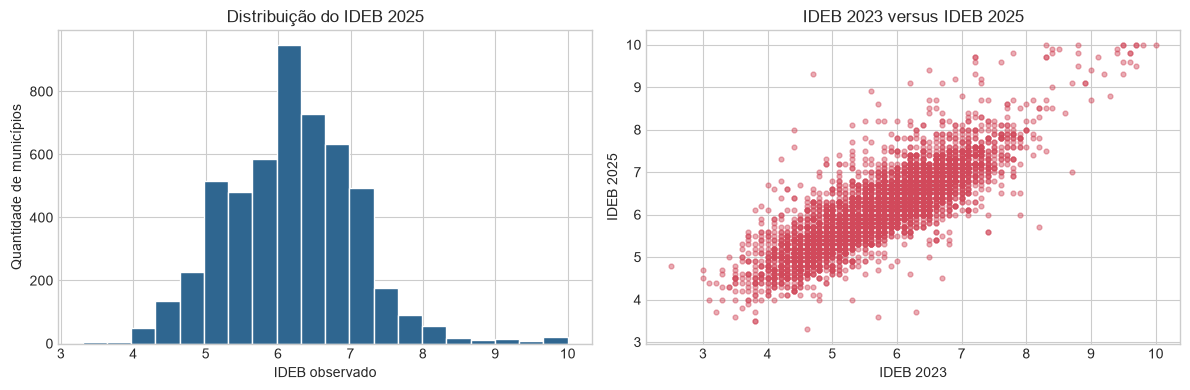

In [5]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(base["VL_OBSERVADO_2025"], bins=20, color="#2F6690", edgecolor="white")
axes[0].set_title("Distribuição do IDEB 2025")
axes[0].set_xlabel("IDEB observado")
axes[0].set_ylabel("Quantidade de municípios")

axes[1].scatter(
    base["VL_OBSERVADO_2023"],
    base["VL_OBSERVADO_2025"],
    s=12,
    alpha=0.45,
    color="#D1495B",
)
axes[1].set_title("IDEB 2023 versus IDEB 2025")
axes[1].set_xlabel("IDEB 2023")
axes[1].set_ylabel("IDEB 2025")

plt.tight_layout()
plt.show()


## 5. Arquivos gerados

O notebook salva:

- `data/processed/ideb_municipal_2023_2025.csv`: base limpa com os municípios que possuem IDEB 2023 e 2025;
- `results/ideb_municipal_2023_2025_resumo.csv`: contagens de controle da preparação.

O próximo notebook deverá integrar essa base com os Indicadores Educacionais, o Censo Escolar e o IBGE.
